# Relative features: subtraction and division

Relative features describe a gap, balance, rate, or proportion. They are often more comparable across records than raw totals. This notebook creates interpretable area ratios from the Ames house-price data.

## Why use relative features?

A house with 2,000 square feet means something different on a tiny lot than on a very large lot. A ratio such as living area divided by lot area captures utilisation. A difference such as total basement area minus finished basement area captures unfinished space.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid',context='notebook')

candidates=[Path('feature-engineering/imputation/houseprice.csv'),Path('../imputation/houseprice.csv'),Path('houseprice.csv')]
path=next((p for p in candidates if p.exists()),None)
if path is None: raise FileNotFoundError('Place houseprice.csv in feature-engineering/imputation/.')
data=pd.read_csv(path,na_values=['NA'])
display(data[['LotArea','GrLivArea','TotalBsmtSF','BsmtFinSF1','BsmtUnfSF','SalePrice']].head())

,LotArea,GrLivArea,TotalBsmtSF,BsmtFinSF1,BsmtUnfSF,SalePrice
0,8450,1710,856,706,150,208500
1,9600,1262,1262,978,284,181500
2,11250,1786,920,486,434,223500
3,9550,1717,756,216,540,140000
4,14260,2198,1145,655,490,250000


## 1. Create differences

Subtraction is useful when two measurements have a natural balance. The unfinished basement area is the total basement area minus finished basement components. Use fill values only when zero truly means absent.

In [2]:
source=data[['LotArea','GrLivArea','TotalBsmtSF','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF']].fillna(0)
relative=pd.DataFrame(index=data.index)
relative['unfinished_basement_area']=source['TotalBsmtSF']-source['BsmtFinSF1']-source['BsmtFinSF2']
relative['above_ground_area']=source['GrLivArea']-source['TotalBsmtSF']
relative['finished_to_unfinished_basement_gap']=source['BsmtFinSF1']-source['BsmtUnfSF']
display(relative.head())
display(relative.describe().T.round(2))

,unfinished_basement_area,above_ground_area,finished_to_unfinished_basement_gap
0,150,854,556
1,284,0,694
2,434,866,52
3,540,961,-324
4,490,1053,165


,count,mean,std,min,25%,50%,75%,max
unfinished_basement_area,1460.0,567.24,441.87,0.0,223.0,477.5,808.00,2336.0
above_ground_area,1460.0,458.03,508.79,-1577.0,0.0,296.5,841.25,2719.0
finished_to_unfinished_basement_gap,1460.0,-123.60,776.46,-2280.0,-742.0,0.0,471.25,5178.0


## 2. Create ratios safely

Division by zero creates infinity and can break a model. The helper below returns zero when the denominator is zero. In a real project, choose the fallback from domain meaning and consider adding a denominator-zero indicator.

In [3]:
def safe_divide(numerator,denominator,fill_value=0.0):
    denominator=denominator.astype(float)
    numerator=numerator.astype(float)
    return numerator.div(denominator.replace(0,np.nan)).fillna(fill_value)

relative['living_to_lot_ratio']=safe_divide(source['GrLivArea'],source['LotArea'])
relative['basement_to_living_ratio']=safe_divide(source['TotalBsmtSF'],source['GrLivArea'])
relative['finished_basement_ratio']=safe_divide(source['BsmtFinSF1']+source['BsmtFinSF2'],source['TotalBsmtSF'])
relative['lot_area_zero']=source['LotArea'].eq(0).astype(int)
display(relative.head())
assert np.isfinite(relative.to_numpy()).all()

,unfinished_basement_area,above_ground_area,finished_to_unfinished_basement_gap,living_to_lot_ratio,basement_to_living_ratio,finished_basement_ratio,lot_area_zero
0,150,854,556,0.202367,0.500585,0.824766,0
1,284,0,694,0.131458,1.000000,0.774960,0
2,434,866,52,0.158756,0.515118,0.528261,0
3,540,961,-324,0.179791,0.440303,0.285714,0
4,490,1053,165,0.154137,0.520928,0.572052,0


## 3. Visualise relative features

Ratios often have a more compact interpretation than raw measurements, but they can still be skewed. Inspect their distributions and their relationship with the target.

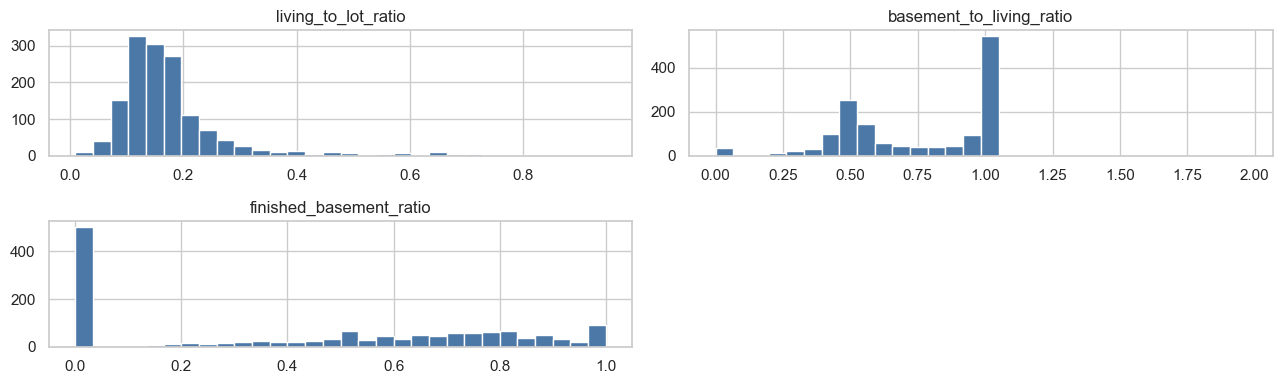

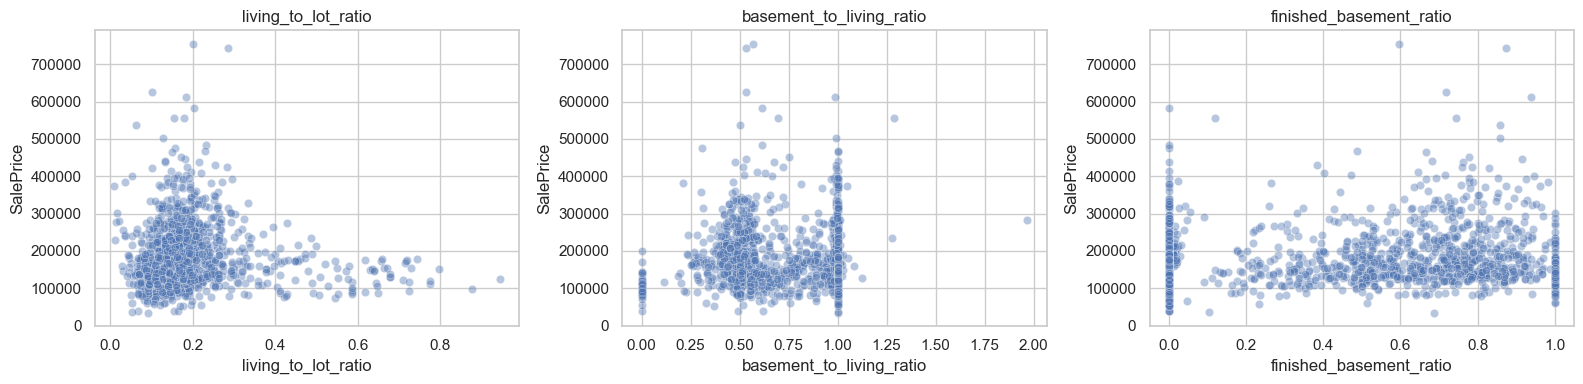

In [4]:
ratio_columns=['living_to_lot_ratio','basement_to_living_ratio','finished_basement_ratio']
relative[ratio_columns].hist(bins=30,figsize=(13,4),color='#4C78A8'); plt.tight_layout(); plt.show()
plot_data=pd.concat([relative[ratio_columns],data[['SalePrice']]],axis=1)
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,column in zip(axes,ratio_columns):
    sns.scatterplot(data=plot_data,x=column,y='SalePrice',alpha=.4,ax=ax); ax.set_title(column)
plt.tight_layout(); plt.show()

## 4. Interpretation and checks

A ratio is unit-aware only when numerator and denominator have compatible meanings. A tiny denominator can create a very large value, so inspect quantiles and decide whether to cap or transform it. Keep the original columns when they still contain useful absolute-size information.

In [5]:
display(relative[ratio_columns].quantile([0,.01,.5,.99,1]).T.round(3))
print('Created columns:',relative.columns.tolist())
print('Rows with zero lot area:',int(relative['lot_area_zero'].sum()))

,0.00,0.01,0.50,0.99,1.00
living_to_lot_ratio,0.009,0.045,0.156,0.678,0.945
basement_to_living_ratio,0.000,0.000,0.782,1.013,1.968
finished_basement_ratio,0.000,0.000,0.504,1.000,1.000


Created columns: ['unfinished_basement_area', 'above_ground_area', 'finished_to_unfinished_basement_gap', 'living_to_lot_ratio', 'basement_to_living_ratio', 'finished_basement_ratio', 'lot_area_zero']
Rows with zero lot area: 0


## Summary

Subtraction exposes gaps and division exposes rates or proportions. Relative features are powerful when their numerator, denominator, units, and zero-handling policy are clearly defined.